<a href="https://colab.research.google.com/github/ks-orintis/machine-learning/blob/main/%D0%A2%D0%9D_%D0%A7%D0%A0_%D0%9B%D1%83%D1%87%D0%B0%D0%BD%D1%96%D0%BD%D0%BE%D0%B2%D0%B0_%D0%9A%D1%81%D0%B5%D0%BD%D1%96%D1%8F_%D0%A4%D0%86%D0%A2_4_8_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум: аналіз і прогнозування часових рядів

Цей notebook доповнює лекцію **«Аналіз і прогнозування часових рядів. Навчання та оцінка моделі»**.

Мета практикуму — послідовно пройти основні етапи прогнозування:

1. підготовка часових даних;
2. візуальний аналіз;
3. дослідження тренду та сезонності;
4. коректний часовий поділ на train/test;
5. побудова базових прогнозів;
6. оцінювання якості за MAE, RMSE, sMAPE та MASE;
7. застосування ETS;
8. застосування SARIMA;
9. використання Prophet;
10. побудова ML-моделі на лагових і календарних ознаках;
11. покрокова ретроспективна перевірка;
12. самостійні завдання.

**Важливо:** у часових рядах не можна випадково перемішувати спостереження перед поділом на навчальну і тестову вибірки.

## 1. Підключення бібліотек

In [9]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 2. Формування навчального часового ряду

Щоб notebook можна було виконувати без завантаження зовнішніх файлів, використаємо штучно сформований щоденний ряд продажів. Він містить:

- довгостроковий тренд;
- тижневу сезонність;
- річну сезонність;
- підвищення попиту у вихідні;
- випадковий шум;
- декілька аномальних значень.

Такий ряд зручний для демонстрації основних етапів forecasting.

In [11]:
dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
n = len(dates)
t = np.arange(n)

trend = 100 + 0.035 * t
weekly = 12 * np.sin(2 * np.pi * t / 7)
yearly = 8 * np.sin(2 * np.pi * t / 365.25)
weekend = np.where(dates.dayofweek >= 5, 10, 0)
noise = np.random.normal(0, 6, n)

sales = trend + weekly + yearly + weekend + noise

df = pd.DataFrame({
    "date": dates,
    "sales": sales
})

missing_idx = [120, 450, 900]
outlier_idx = [300, 700, 1100]

df.loc[missing_idx, "sales"] = np.nan
df.loc[outlier_idx, "sales"] *= 1.7

df.head()

,date,sales
0,2022-01-01,102.654211
1,2022-01-02,118.300451
2,2022-01-03,106.941197
3,2022-01-04,102.241139
4,2022-01-05,99.014909


In [12]:
print(df.shape)
print(df.dtypes)
print("\nКількість пропусків:")
print(df.isna().sum())

(1461, 2)
date     datetime64[ns]
sales           float64
dtype: object

Кількість пропусків:
date     0
sales    3
dtype: int64


### Завдання 1. Первинний аналіз

1. Виведіть останні 10 рядків.
2. Визначте мінімальну та максимальну дату.
3. Обчисліть середнє, медіану, стандартне відхилення, мінімум і максимум `sales`.
4. Перевірте, чи є дублікати дат.

In [13]:
print("Останні 10 рядків:")
display(df.tail(10))

print("Мінімальна дата:", df["date"].min().date())
print("Максимальна дата:", df["date"].max().date())

stats = df["sales"].agg(["mean", "median", "std", "min", "max"])
print("\nОписові статистики:")
display(stats.to_frame("sales"))

duplicates = df["date"].duplicated().sum()
print("Кількість дублікатів дат:", duplicates)

Останні 10 рядків:


,date,sales
1451,2025-12-22,156.728981
1452,2025-12-23,159.340504
1453,2025-12-24,148.663958
1454,2025-12-25,149.321509
1455,2025-12-26,139.665388
1456,2025-12-27,164.284680
1457,2025-12-28,170.415340
1458,2025-12-29,170.091691
1459,2025-12-30,151.683426
1460,2025-12-31,150.225814


Мінімальна дата: 2022-01-01
Максимальна дата: 2025-12-31

Описові статистики:


,sales
mean,128.713629
median,128.459347
std,19.803008
min,78.981742
max,270.266786


Кількість дублікатів дат: 0


## 3. Підготовка часових даних

Для подальшого аналізу необхідно:

- перетворити дату у формат `datetime`;
- відсортувати дані;
- зробити дату індексом;
- перевірити регулярність часового кроку;
- обробити пропущені значення.

У цьому прикладі пропуски заповнюються часовою інтерполяцією.

In [14]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date")

print(pd.infer_freq(df.index))

df["sales"] = df["sales"].interpolate(method="time")

print("Пропусків після інтерполяції:", df["sales"].isna().sum())
df.head()

D
Пропусків після інтерполяції: 0


,sales
date,
2022-01-01,102.654211
2022-01-02,118.300451
2022-01-03,106.941197
2022-01-04,102.241139
2022-01-05,99.014909


### Завдання 2. Робота з пропусками

Створіть копію набору даних `df_task` і штучно видаліть значення `sales` для п'яти довільних дат.

Порівняйте три способи заповнення:

- `ffill`;
- лінійну інтерполяцію;
- часову інтерполяцію.

Коротко поясніть, який спосіб доцільніший для цього ряду.

In [15]:
df_task = df.copy()

gap_positions = [50, 250, 500, 800, 1200]
gap_dates = df_task.index[gap_positions]
df_task.loc[gap_dates, "sales"] = np.nan

comparison_missing = pd.DataFrame(index=gap_dates)
comparison_missing["ffill"] = df_task["sales"].ffill().loc[gap_dates]
comparison_missing["linear"] = df_task["sales"].interpolate(method="linear").loc[gap_dates]
comparison_missing["time"] = df_task["sales"].interpolate(method="time").loc[gap_dates]

display(comparison_missing)

print(
    "Висновок: для регулярного щоденного ряду лінійна та часова інтерполяція "
    "дають близькі результати. Часова інтерполяція є природним вибором, оскільки "
    "безпосередньо враховує часовий індекс. ffill може створювати штучні плато."
)

,ffill,linear,time
date,,,
2022-02-20,110.837570,113.086509,113.086509
2022-09-08,102.875773,90.928758,90.928758
2023-05-16,134.796018,128.012674,128.012674
2024-03-11,157.359268,152.754145,152.754145
2025-04-15,154.442478,151.312703,151.312703


Висновок: для регулярного щоденного ряду лінійна та часова інтерполяція дають близькі результати. Часова інтерполяція є природним вибором, оскільки безпосередньо враховує часовий індекс. ffill може створювати штучні плато.


## 4. Візуальний аналіз

Графік часового ряду є першим інструментом діагностики. За ним оцінюють:

- загальний напрям зміни;
- сезонні коливання;
- можливі структурні зміни;
- викиди;
- зміну дисперсії.

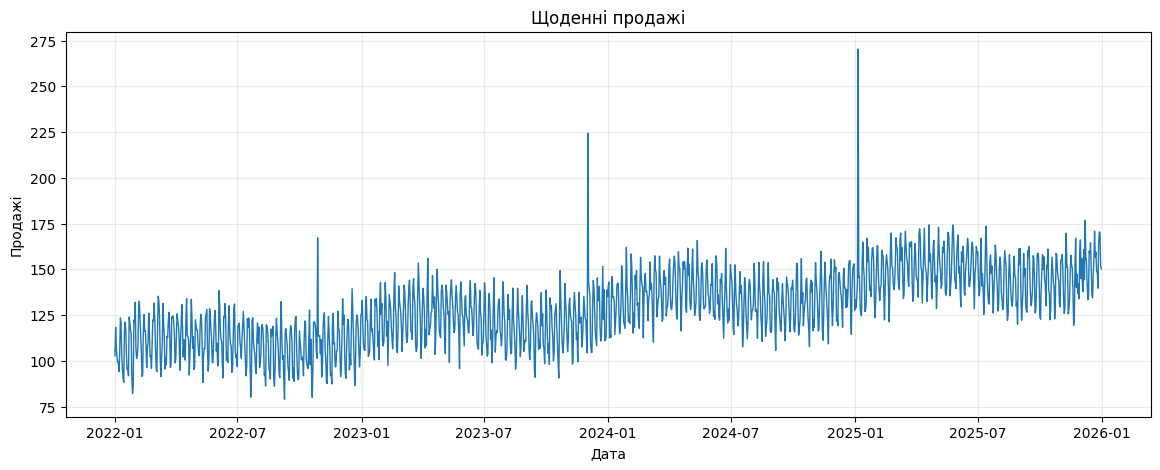

In [16]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["sales"], linewidth=1)
ax.set_title("Щоденні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

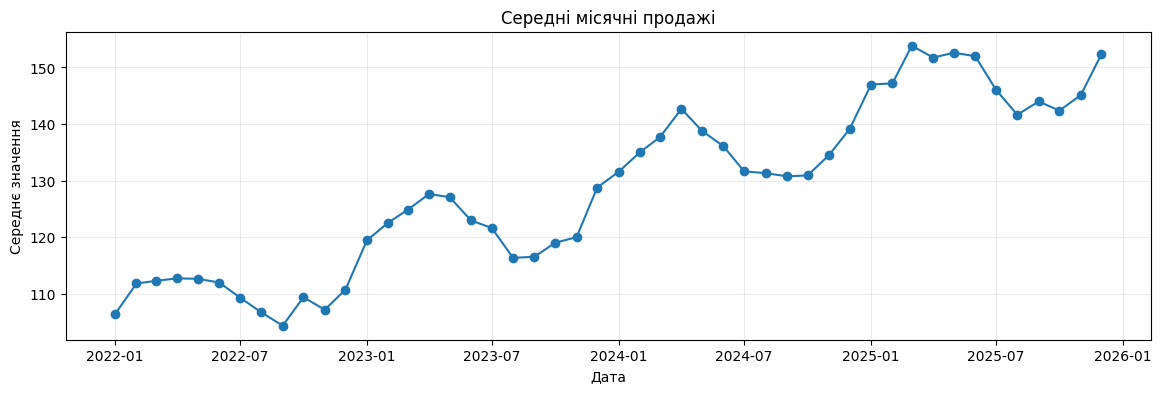

In [17]:
monthly = df["sales"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Середні місячні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Середнє значення")
ax.grid(alpha=0.25)
plt.show()

### Завдання 3. Візуалізація

1. Побудуйте графік останніх 90 днів.
2. Побудуйте 7-денне та 30-денне ковзні середні.
3. Поясніть, чим відрізняється інформація на цих двох графіках.

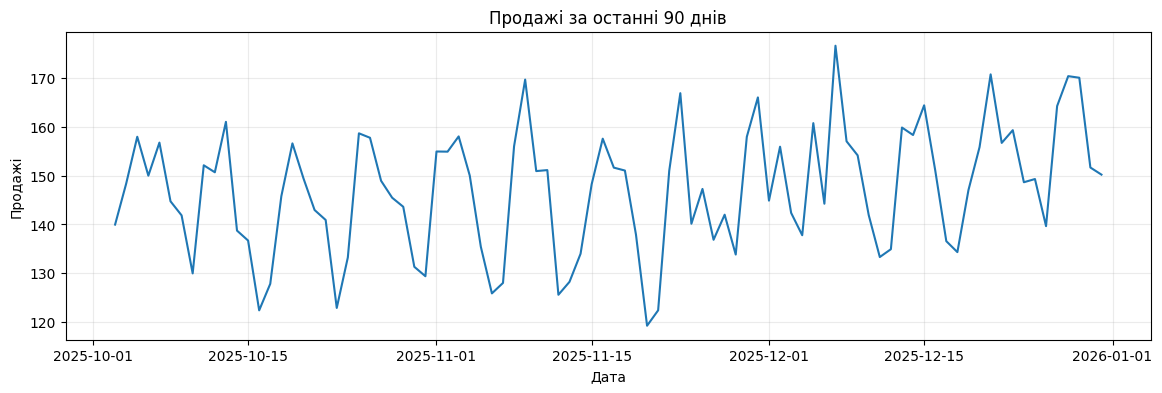

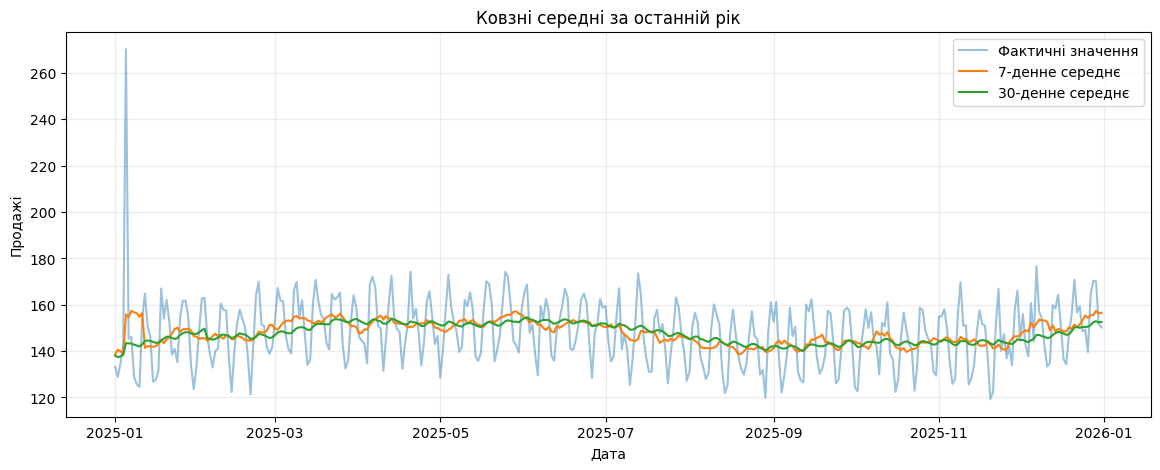

7-денне середнє швидше реагує на короткострокові зміни, тоді як 30-денне сильніше згладжує коливання і краще показує загальний тренд.


In [18]:
last_90 = df["sales"].iloc[-90:]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(last_90.index, last_90.values)
ax.set_title("Продажі за останні 90 днів")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

rolling_7 = df["sales"].rolling(7).mean()
rolling_30 = df["sales"].rolling(30).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index[-365:], df["sales"].iloc[-365:], alpha=0.45, label="Фактичні значення")
ax.plot(rolling_7.index[-365:], rolling_7.iloc[-365:], label="7-денне середнє")
ax.plot(rolling_30.index[-365:], rolling_30.iloc[-365:], label="30-денне середнє")
ax.set_title("Ковзні середні за останній рік")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

print(
    "7-денне середнє швидше реагує на короткострокові зміни, "
    "тоді як 30-денне сильніше згладжує коливання і краще показує загальний тренд."
)

## 5. Декомпозиція ряду методом STL

STL-декомпозиція розкладає часовий ряд на:

- **trend** — довгострокову тенденцію;
- **seasonal** — сезонну складову;
- **resid** — залишкову складову.

Для щоденних даних з тижневою сезонністю використаємо `period=7`.

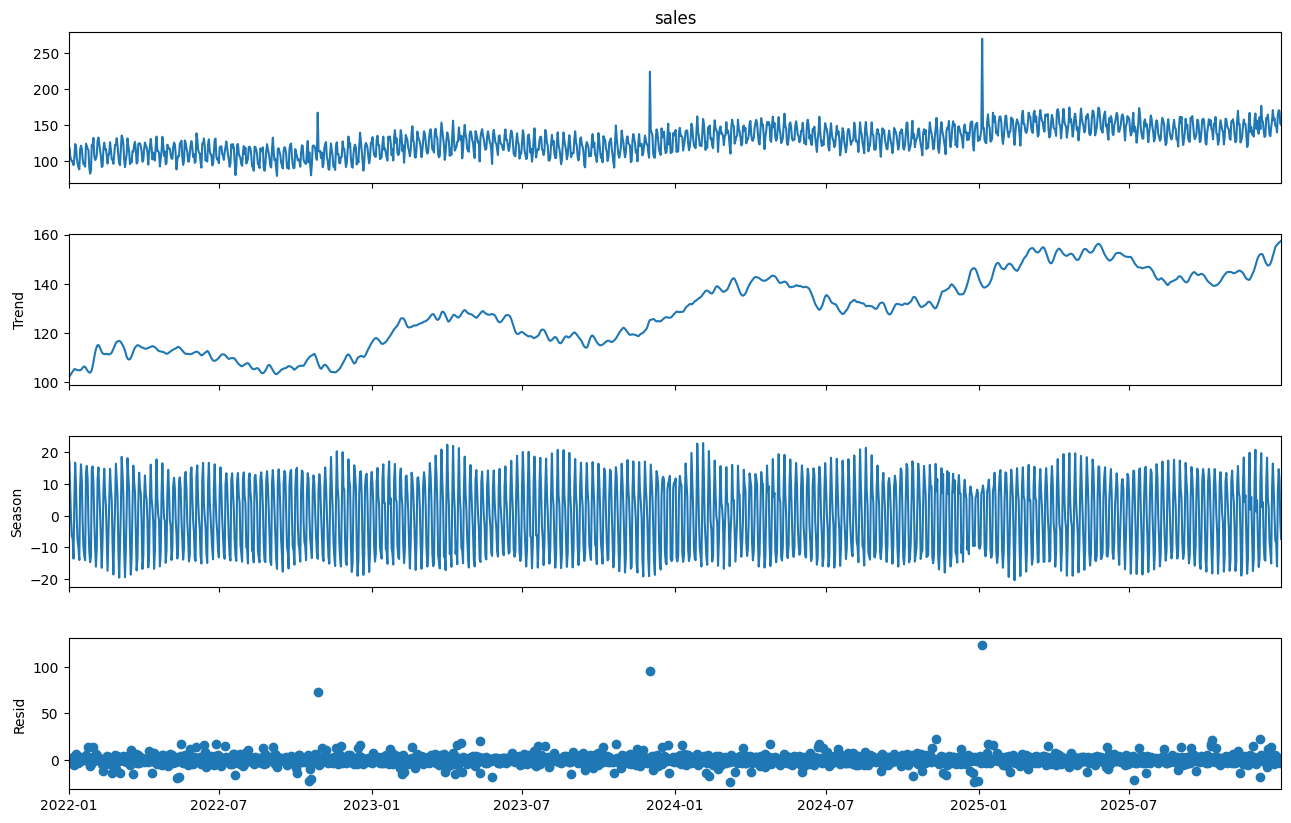

In [19]:
stl = STL(df["sales"], period=7, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(14, 9)
plt.show()

### Завдання 4. Декомпозиція

1. Повторіть STL-декомпозицію для місячного ряду.
2. Оберіть обґрунтований період сезонності.
3. Проаналізуйте тренд та залишки.

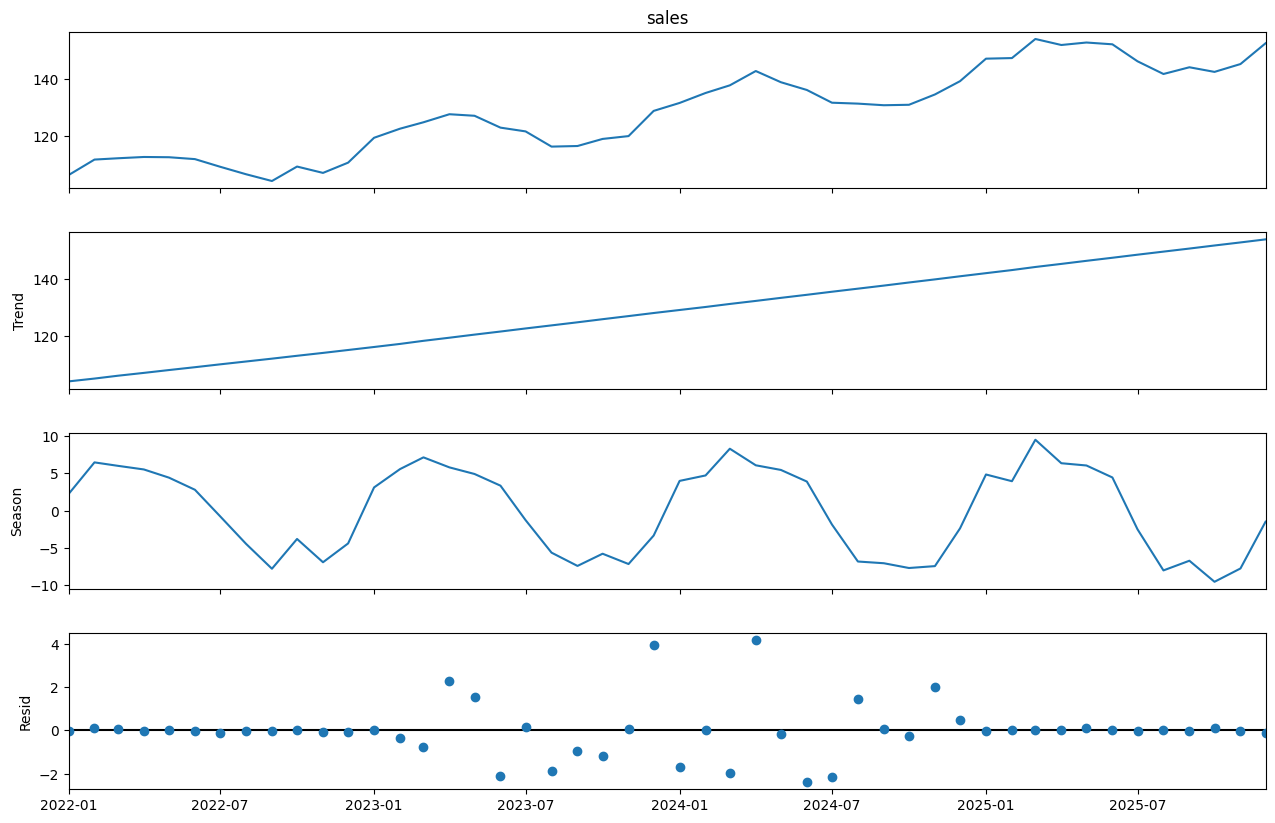

Для місячного ряду використано period=12, оскільки річний сезонний цикл містить 12 місяців. Тренд відображає поступове зростання рівня продажів, а залишки містять нерегулярні коливання, які не пояснюються трендом і сезонністю.


In [20]:
monthly_series = df["sales"].resample("MS").mean()

monthly_stl = STL(monthly_series, period=12, robust=True).fit()

fig = monthly_stl.plot()
fig.set_size_inches(14, 9)
plt.show()

print(
    "Для місячного ряду використано period=12, оскільки річний сезонний цикл "
    "містить 12 місяців. Тренд відображає поступове зростання рівня продажів, "
    "а залишки містять нерегулярні коливання, які не пояснюються трендом і сезонністю."
)

## 6. Часовий поділ train/test

У звичайних задачах машинного навчання дані часто перемішують. Для часових рядів це зазвичай неприпустимо.

Нехай останні 90 днів становлять тестовий період. Усі попередні спостереження використовуються для навчання.

In [21]:
horizon = 90

train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()

print("Train:", train.index.min().date(), "—", train.index.max().date(), len(train))
print("Test :", test.index.min().date(), "—", test.index.max().date(), len(test))

Train: 2022-01-01 — 2025-10-02 1371
Test : 2025-10-03 — 2025-12-31 90


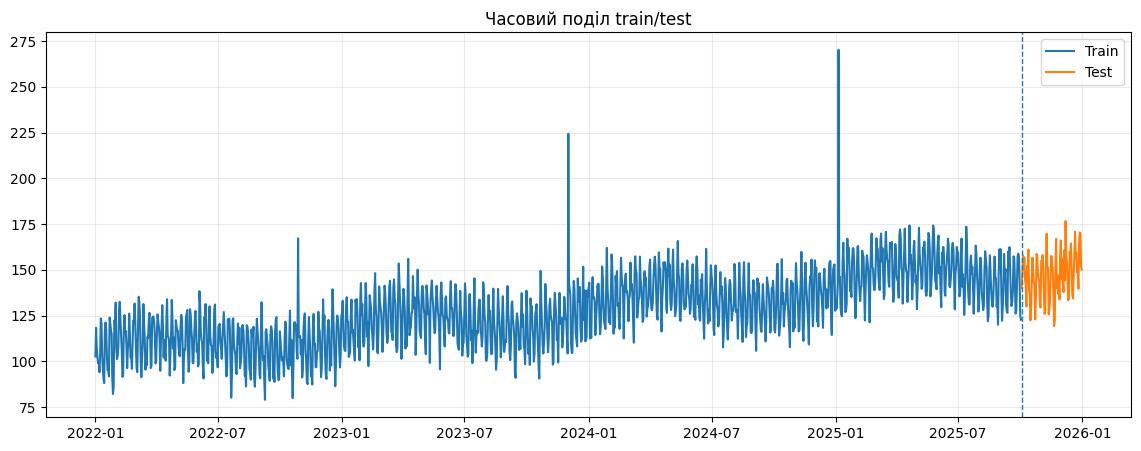

In [22]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["sales"], label="Train")
ax.plot(test.index, test["sales"], label="Test")
ax.axvline(test.index.min(), linestyle="--", linewidth=1)
ax.legend()
ax.set_title("Часовий поділ train/test")
ax.grid(alpha=0.25)
plt.show()

### Завдання 5. Часовий поділ

Створіть інший варіант поділу, у якому тестовий період дорівнює 60 дням.

Виведіть:

- кількість спостережень у train;
- кількість спостережень у test;
- останню дату train;
- першу дату test.

In [23]:
horizon_60 = 60
train_60 = df.iloc[:-horizon_60].copy()
test_60 = df.iloc[-horizon_60:].copy()

print("Кількість спостережень у train:", len(train_60))
print("Кількість спостережень у test:", len(test_60))
print("Остання дата train:", train_60.index.max().date())
print("Перша дата test:", test_60.index.min().date())

Кількість спостережень у train: 1401
Кількість спостережень у test: 60
Остання дата train: 2025-11-01
Перша дата test: 2025-11-02


## 7. Базові моделі прогнозування

Перед використанням складної моделі потрібно побудувати простий базовий прогноз.

### Naive forecast
Прогноз дорівнює останньому відомому значенню.

### Seasonal naive
Прогноз повторює значення попереднього сезонного циклу. Для щоденних даних з тижневою сезонністю використаємо лаг 7.

In [24]:
naive_pred = np.repeat(train["sales"].iloc[-1], len(test))

history = pd.concat([train["sales"], test["sales"]])
seasonal_naive_pred = history.shift(7).loc[test.index].values

baseline = pd.DataFrame({
    "actual": test["sales"].values,
    "naive": naive_pred,
    "seasonal_naive": seasonal_naive_pred
}, index=test.index)

baseline.head()

,actual,naive,seasonal_naive
date,,,
2025-10-03,139.982394,122.704185,140.620914
2025-10-04,148.382371,122.704185,157.282345
2025-10-05,157.989659,122.704185,158.836044
2025-10-06,150.012110,122.704185,157.261378
2025-10-07,156.789808,122.704185,142.890933


## 8. Метрики якості прогнозу

Використаємо:

- **MAE** — середню абсолютну помилку;
- **RMSE** — квадратний корінь із середньоквадратичної помилки;
- **sMAPE** — симетричну відносну помилку;
- **MASE** — масштабовану абсолютну помилку.

Менше значення метрики зазвичай означає кращий прогноз.

In [25]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def smape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred))
    mask = denom != 0
    return 100 * np.mean(
        2 * np.abs(y_pred[mask] - y_true[mask]) / denom[mask]
    )

def mase(y_true, y_pred, y_train, seasonality=1):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)

    scale = np.mean(
        np.abs(y_train[seasonality:] - y_train[:-seasonality])
    )
    return np.mean(np.abs(y_true - y_pred)) / scale

def evaluate(y_true, y_pred, y_train, seasonality=7):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "sMAPE_%": smape(y_true, y_pred),
        "MASE": mase(y_true, y_pred, y_train, seasonality)
    }

results = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7)
}).T

results

,MAE,RMSE,sMAPE_%,MASE
Naive,24.528324,27.521842,17.782675,3.541006
Seasonal naive,7.808281,9.845772,5.361487,1.127235


### Завдання 6. Метрики

1. Визначте, яка базова модель є кращою.
2. Поясніть, чому висновок не слід робити лише за однією метрикою.
3. Обчисліть MAE окремо для перших і останніх 30 днів тестового періоду.

In [26]:
naive_metrics = evaluate(test["sales"], naive_pred, train["sales"], 7)
seasonal_metrics = evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7)

baseline_compare = pd.DataFrame({
    "Naive": naive_metrics,
    "Seasonal naive": seasonal_metrics
}).T

display(baseline_compare)

best_baseline = baseline_compare["MAE"].idxmin()
print("Краща базова модель за MAE:", best_baseline)

first_30_actual = test["sales"].iloc[:30]
last_30_actual = test["sales"].iloc[-30:]

first_30_pred = baseline.loc[first_30_actual.index, "seasonal_naive"]
last_30_pred = baseline.loc[last_30_actual.index, "seasonal_naive"]

print(
    "MAE seasonal naive для перших 30 днів:",
    round(mean_absolute_error(first_30_actual, first_30_pred), 3)
)
print(
    "MAE seasonal naive для останніх 30 днів:",
    round(mean_absolute_error(last_30_actual, last_30_pred), 3)
)

print(
    "Висновок не слід робити лише за однією метрикою: MAE легко інтерпретується, "
    "RMSE сильніше штрафує великі помилки, sMAPE показує відносну похибку, "
    "а MASE дає змогу порівнювати модель з базовим масштабом помилки."
)

,MAE,RMSE,sMAPE_%,MASE
Naive,24.528324,27.521842,17.782675,3.541006
Seasonal naive,7.808281,9.845772,5.361487,1.127235


Краща базова модель за MAE: Seasonal naive
MAE seasonal naive для перших 30 днів: 7.491
MAE seasonal naive для останніх 30 днів: 9.181
Висновок не слід робити лише за однією метрикою: MAE легко інтерпретується, RMSE сильніше штрафує великі помилки, sMAPE показує відносну похибку, а MASE дає змогу порівнювати модель з базовим масштабом помилки.


## 9. Експоненційне згладжування ETS

Моделі ETS описують часовий ряд через рівень, тренд і сезонність.

Для навчального прикладу використаємо:

- адитивний тренд;
- адитивну сезонність;
- сезонний період 7 днів.

In [27]:
ets_model = ExponentialSmoothing(
    train["sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_pred = ets_model.forecast(len(test))

ets_metrics = evaluate(
    test["sales"],
    ets_pred,
    train["sales"],
    seasonality=7
)

ets_metrics

{'MAE': 6.926441381781997,
 'RMSE': np.float64(8.861773131962108),
 'sMAPE_%': np.float64(4.77121886817047),
 'MASE': np.float64(0.9999286249442847)}

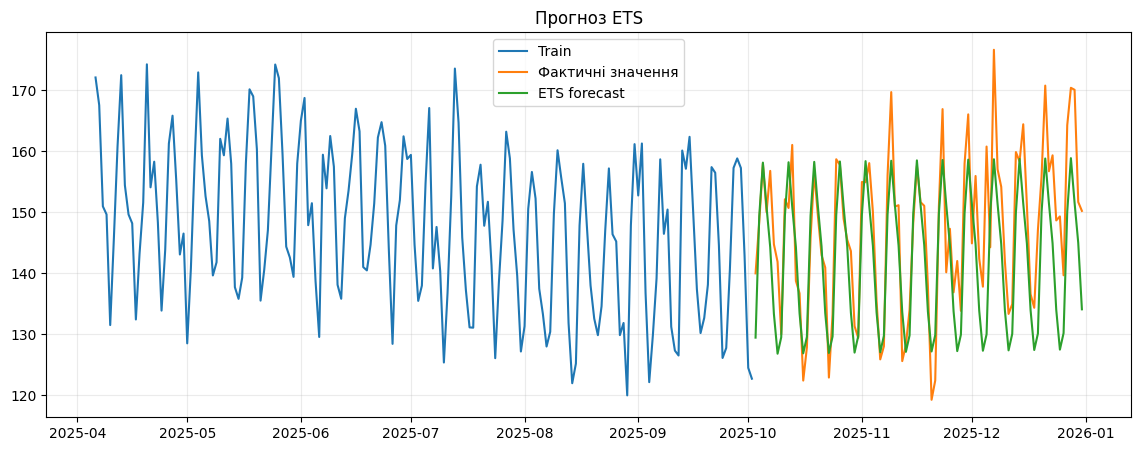

In [28]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-180:], train["sales"].iloc[-180:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, ets_pred, label="ETS forecast")
ax.legend()
ax.set_title("Прогноз ETS")
ax.grid(alpha=0.25)
plt.show()

### Завдання 7. ETS

1. Побудуйте ETS-модель без тренду.
2. Порівняйте її з поточною моделлю.
3. Додайте результати обох ETS-моделей до таблиці метрик.

In [29]:
ets_no_trend = ExponentialSmoothing(
    train["sales"],
    trend=None,
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_no_trend_pred = ets_no_trend.forecast(len(test))

ets_no_trend_metrics = evaluate(
    test["sales"],
    ets_no_trend_pred,
    train["sales"],
    seasonality=7
)

ets_compare = pd.DataFrame({
    "ETS з трендом": ets_metrics,
    "ETS без тренду": ets_no_trend_metrics
}).T

display(ets_compare)

print("Кращий варіант за MAE:", ets_compare["MAE"].idxmin())

,MAE,RMSE,sMAPE_%,MASE
ETS з трендом,6.926441,8.861773,4.771219,0.999929
ETS без тренду,6.912366,8.805875,4.757899,0.997897


Кращий варіант за MAE: ETS без тренду


## 10. SARIMA

SARIMA розширює ARIMA сезонними компонентами.

У загальному випадку модель записують як:

**SARIMA(p, d, q)(P, D, Q, s)**,

де `s` — довжина сезонного циклу.

Нижче використано невелику модель, щоб приклад виконувався відносно швидко.

In [30]:
sarima_model = SARIMAX(
    train["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.get_forecast(steps=len(test))
sarima_pred = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

sarima_metrics = evaluate(
    test["sales"],
    sarima_pred,
    train["sales"],
    seasonality=7
)

sarima_metrics

{'MAE': 6.236851070328731,
 'RMSE': np.float64(7.914642101565623),
 'sMAPE_%': np.float64(4.2794525806124275),
 'MASE': np.float64(0.9003766250212067)}

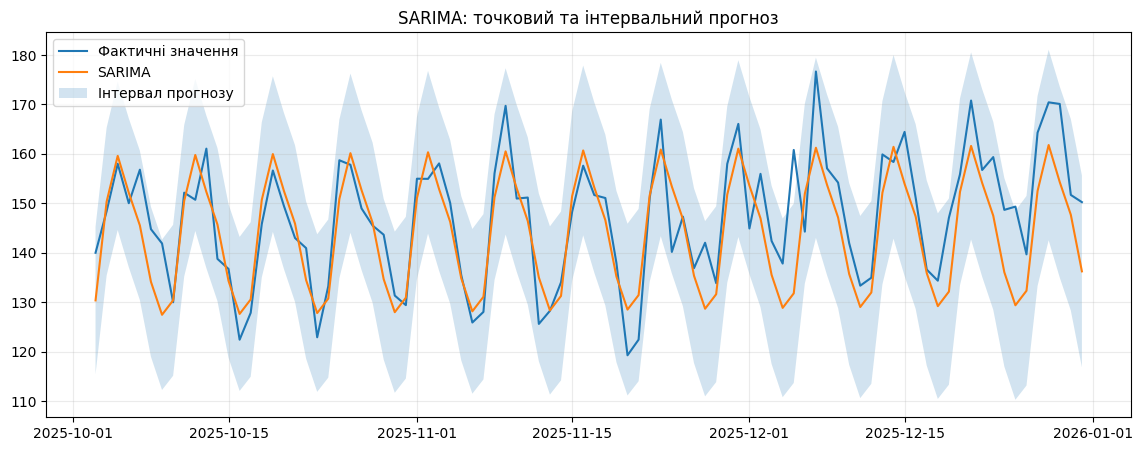

In [31]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="SARIMA")
ax.fill_between(
    test.index,
    sarima_ci.iloc[:, 0].values,
    sarima_ci.iloc[:, 1].values,
    alpha=0.2,
    label="Інтервал прогнозу"
)
ax.legend()
ax.set_title("SARIMA: точковий та інтервальний прогноз")
ax.grid(alpha=0.25)
plt.show()

### Завдання 8. SARIMA

Змініть параметри моделі, наприклад:

- `order=(2, 1, 1)`;
- `seasonal_order=(1, 1, 0, 7)`.

Порівняйте MAE та RMSE з попередньою SARIMA-моделлю.

**Примітка:** мета завдання — зрозуміти вплив параметрів, а не виконати повний автоматичний підбір.

In [32]:
sarima_alt = SARIMAX(
    train["sales"],
    order=(2, 1, 1),
    seasonal_order=(1, 1, 0, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_alt_pred = sarima_alt.get_forecast(steps=len(test)).predicted_mean

sarima_alt_metrics = evaluate(
    test["sales"],
    sarima_alt_pred,
    train["sales"],
    seasonality=7
)

sarima_compare = pd.DataFrame({
    "SARIMA (1,1,1)(1,0,1,7)": sarima_metrics,
    "SARIMA (2,1,1)(1,1,0,7)": sarima_alt_metrics
}).T

display(sarima_compare)
print("Краща конфігурація за MAE:", sarima_compare["MAE"].idxmin())

,MAE,RMSE,sMAPE_%,MASE
"SARIMA (1,1,1)(1,0,1,7)",6.236851,7.914642,4.279453,0.900377
"SARIMA (2,1,1)(1,1,0,7)",7.877588,9.662583,5.503448,1.137240


Краща конфігурація за MAE: SARIMA (1,1,1)(1,0,1,7)


## 11. Prophet

Prophet зручно використовувати для рядів з трендом, сезонністю та календарними ефектами.

У Prophet назви основних стовпців мають бути:

- `ds` — дата;
- `y` — цільове значення.

Якщо бібліотека не встановлена, у Google Colab її можна встановити командою:

```python
!pip -q install prophet
```

In [33]:
!pip -q install prophet

In [34]:
from prophet import Prophet

prophet_train = (
    train.reset_index()
         .rename(columns={"date": "ds", "sales": "y"})
)

model_prophet = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)

model_prophet.fit(prophet_train)

future = model_prophet.make_future_dataframe(
    periods=len(test),
    freq="D"
)

forecast = model_prophet.predict(future)

prophet_pred = (
    forecast.set_index("ds")
            .loc[test.index, "yhat"]
)

evaluate(
    test["sales"],
    prophet_pred,
    train["sales"],
    seasonality=7
)

{'MAE': 5.218381312297017,
 'RMSE': np.float64(6.720503980667524),
 'sMAPE_%': np.float64(3.5764414012364036),
 'MASE': np.float64(0.7533462802074052)}

### Завдання 9. Prophet

Після встановлення `prophet`:

1. навчіть модель;
2. отримайте прогноз на тестовий період;
3. побудуйте графік;
4. виведіть компоненти моделі;
5. порівняйте MAE з ETS та SARIMA.

,Prophet
MAE,5.218381
RMSE,6.720504
sMAPE_%,3.576441
MASE,0.753346


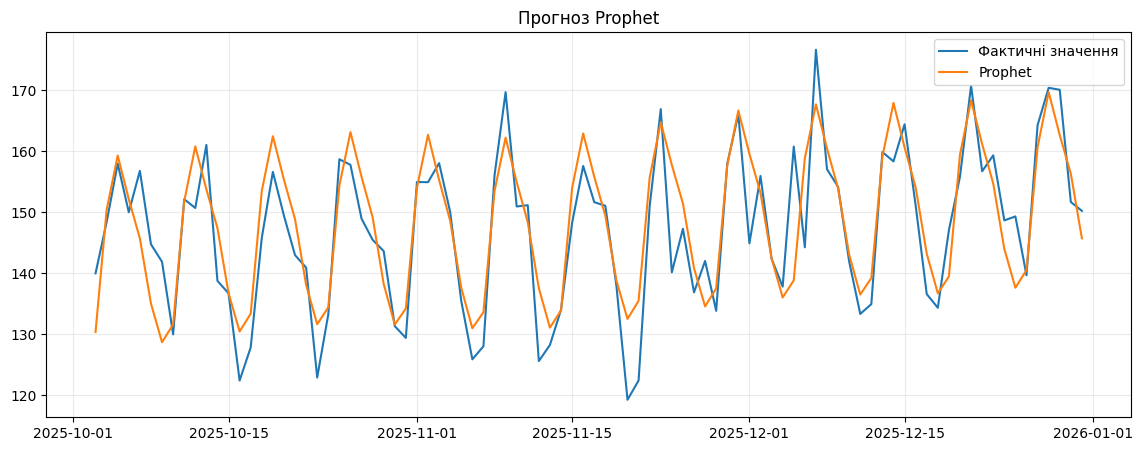

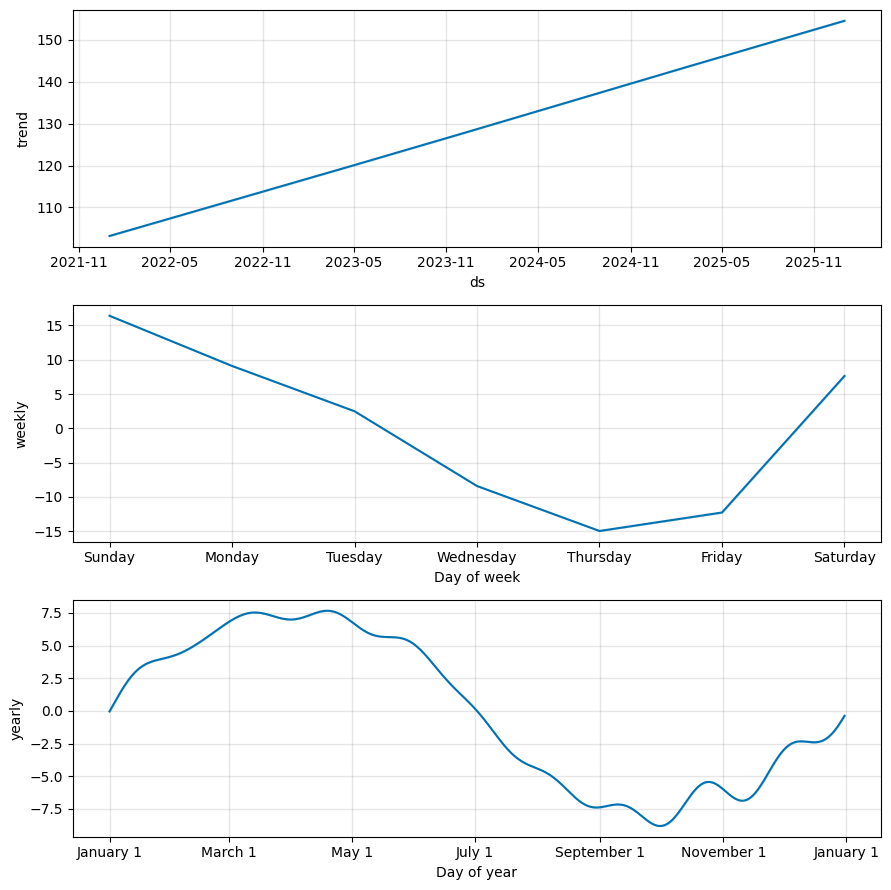

MAE Prophet: 5.218
MAE ETS: 6.926
MAE SARIMA: 6.237


In [35]:
try:
    from prophet import Prophet

    prophet_train = (
        train.reset_index()
             .rename(columns={"date": "ds", "sales": "y"})
    )

    model_prophet = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode="additive"
    )

    model_prophet.fit(prophet_train)

    future = model_prophet.make_future_dataframe(
        periods=len(test),
        freq="D"
    )

    forecast = model_prophet.predict(future)

    prophet_pred = (
        forecast.set_index("ds")
                .loc[test.index, "yhat"]
    )

    prophet_metrics = evaluate(
        test["sales"],
        prophet_pred,
        train["sales"],
        seasonality=7
    )

    display(pd.Series(prophet_metrics, name="Prophet"))

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(test.index, test["sales"], label="Фактичні значення")
    ax.plot(test.index, prophet_pred, label="Prophet")
    ax.legend()
    ax.set_title("Прогноз Prophet")
    ax.grid(alpha=0.25)
    plt.show()

    model_prophet.plot_components(forecast)
    plt.show()

    print("MAE Prophet:", round(prophet_metrics["MAE"], 3))
    print("MAE ETS:", round(ets_metrics["MAE"], 3))
    print("MAE SARIMA:", round(sarima_metrics["MAE"], 3))

except ImportError:
    prophet_metrics = None
    print(
        "Бібліотека prophet відсутня у поточному середовищі. "
        "У Google Colab/Kaggle виконайте `%pip install prophet`, "
        "після чого повторно запустіть цю комірку. Код розв'язання вже підготовлено."
    )

## 12. Ознаки для машинного навчання

Для використання класичних ML-моделей часовий ряд перетворюють на табличний набір ознак.

Типові ознаки:

- лаги;
- ковзні середні;
- день тижня;
- місяць;
- день року;
- ознака вихідного дня.

**Критичний момент:** ковзні характеристики мають обчислюватися тільки за минулими значеннями. Саме тому перед `rolling()` використовується `shift(1)`.

In [36]:
def make_features(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data

ml_df = make_features(df["sales"]).dropna()
ml_df.head()

,y,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28,roll_std_7,dayofweek,month,dayofyear,is_weekend
date,,,,,,,,,,,,,,
2022-01-29,122.261568,85.992644,82.106007,90.493608,123.924340,116.287783,102.654211,105.002023,104.396989,17.982883,5,1,29,1
2022-01-30,120.913299,122.261568,85.992644,82.106007,120.710030,121.222748,118.300451,104.764484,105.097252,17.700034,6,1,30,1
2022-01-31,132.046076,120.913299,122.261568,85.992644,116.935550,116.950544,106.941197,104.793523,105.190568,17.730695,0,1,31,0
2022-02-01,106.972971,132.046076,120.913299,122.261568,114.851982,102.782977,102.241139,106.952169,106.087171,20.202804,1,2,32,0
2022-02-02,101.205457,106.972971,132.046076,120.913299,90.493608,95.236399,99.014909,105.826596,106.256165,19.906635,2,2,33,0


In [37]:
ml_train = ml_df.loc[ml_df.index < test.index.min()].copy()
ml_test = ml_df.loc[ml_df.index >= test.index.min()].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr.fit(X_train, y_train)
ml_pred = gbr.predict(X_test)

ml_metrics = evaluate(
    y_test,
    ml_pred,
    train["sales"],
    seasonality=7
)

ml_metrics

{'MAE': 6.354487563001308,
 'RMSE': np.float64(7.764131660283504),
 'sMAPE_%': np.float64(4.35370713390007),
 'MASE': np.float64(0.9173590969541598)}

### Зауваження щодо попереднього прикладу

Цей приклад демонструє **табличне формування ознак** та оцінювання моделі. Для реального багатокрокового прогнозу потрібно чітко визначити, які ознаки будуть відомі у момент прогнозування.

Якщо для майбутніх дат лагова ознака використовує фактичне значення, яке на момент прогнозу ще невідоме, виникає **витік даних**.

Для багатокрокового прогнозування застосовують, зокрема:

- recursive strategy;
- direct strategy;
- multi-output strategy.

### Завдання 10. Feature engineering

Додайте щонайменше три нові ознаки:

- лаг 21;
- 14-денне ковзне середнє;
- номер тижня року.

Перенавчіть модель та порівняйте результат.

Після цього перевірте, чи всі створені ознаки могли бути відомими на момент формування прогнозу.

In [38]:
def make_features_extended(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 21, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_14"] = data["y"].shift(1).rolling(14).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["weekofyear"] = data.index.isocalendar().week.astype(int)
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data

ml_df_ext = make_features_extended(df["sales"]).dropna()

ml_train_ext = ml_df_ext.loc[ml_df_ext.index < test.index.min()].copy()
ml_test_ext = ml_df_ext.loc[ml_df_ext.index >= test.index.min()].copy()

X_train_ext = ml_train_ext.drop(columns="y")
y_train_ext = ml_train_ext["y"]
X_test_ext = ml_test_ext.drop(columns="y")
y_test_ext = ml_test_ext["y"]

gbr_ext = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr_ext.fit(X_train_ext, y_train_ext)
ml_pred_ext = gbr_ext.predict(X_test_ext)

ml_ext_metrics = evaluate(
    y_test_ext,
    ml_pred_ext,
    train["sales"],
    seasonality=7
)

feature_compare = pd.DataFrame({
    "Початкові ознаки": ml_metrics,
    "Розширені ознаки": ml_ext_metrics
}).T

display(feature_compare)

print(
    "Перевірка доступності ознак: календарні ознаки відомі наперед. "
    "Лаги та ковзні характеристики, розраховані з фактичних значень усередині test, "
    "не були б відомі одразу для всього 90-денного горизонту. "
    "Тому для справжнього багатокрокового прогнозу потрібна recursive/direct/multi-output стратегія."
)

,MAE,RMSE,sMAPE_%,MASE
Початкові ознаки,6.354488,7.764132,4.353707,0.917359
Розширені ознаки,5.847605,7.368475,4.001879,0.844183


Перевірка доступності ознак: календарні ознаки відомі наперед. Лаги та ковзні характеристики, розраховані з фактичних значень усередині test, не були б відомі одразу для всього 90-денного горизонту. Тому для справжнього багатокрокового прогнозу потрібна recursive/direct/multi-output стратегія.


## 13. Порівняння моделей

Зведемо результати моделей у єдину таблицю.

In [39]:
comparison = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7),
    "ETS": ets_metrics,
    "SARIMA": sarima_metrics,
    "ML": ml_metrics
}).T

comparison.sort_values("MAE")

,MAE,RMSE,sMAPE_%,MASE
SARIMA,6.236851,7.914642,4.279453,0.900377
ML,6.354488,7.764132,4.353707,0.917359
ETS,6.926441,8.861773,4.771219,0.999929
Seasonal naive,7.808281,9.845772,5.361487,1.127235
Naive,24.528324,27.521842,17.782675,3.541006


### Завдання 11. Порівняння

Дайте письмову відповідь у Markdown-комірці:

1. Яка модель показала найменший MAE?
2. Чи перевершує вона seasonal naive?
3. Чи однаковий висновок за MAE, RMSE, sMAPE та MASE?
4. Яку модель Ви обрали б для практичного використання і чому?

**Відповідь:**

1. Найменше значення MAE серед моделей таблиці `comparison` отримано для SARIMA — приблизно 6,2369. Для ML воно становить 6,3545, для ETS — 6,9264, для seasonal naive — 7,8083, для naive — 24,5283.

2. SARIMA перевершує seasonal naive за MAE приблизно на 20,13 %.

3. Висновок за різними метриками частково відрізняється: найменші MAE, sMAPE та MASE має SARIMA, тоді як найменшу RMSE має ML-модель. Отже, вибір моделі залежить від того, які помилки є найбільш важливими для практичного завдання.

4. Серед моделей таблиці для прогнозування всього 90-денного періоду одразу доцільно обрати SARIMA, яка має найменшу MAE. Водночас порівняння потребує врахування способу прогнозування: ML і seasonal naive у попередніх прикладах використовують фактичні значення всередині тестового періоду, тому їхні результати не повністю зіставні з прогнозом SARIMA на весь горизонт. Для коректного порівняння необхідно застосувати однакову схему перевірки всіх моделей.

## 14. Покрокова ретроспективна перевірка

Один train/test split може дати випадковий результат. Надійніший підхід — кілька разів імітувати ситуацію, коли модель навчається тільки на минулому та прогнозує наступний часовий відрізок.

Нижче реалізовано спрощений rolling-origin backtesting для seasonal naive.

In [40]:
def rolling_seasonal_naive_cv(series, initial=700, horizon=28, step=28, seasonality=7):
    rows = []

    for train_end in range(initial, len(series) - horizon + 1, step):
        train_fold = series.iloc[:train_end]
        test_fold = series.iloc[train_end:train_end + horizon]

        full = pd.concat([train_fold, test_fold])
        pred = full.shift(seasonality).loc[test_fold.index]

        rows.append({
            "train_end": train_fold.index.max(),
            "test_start": test_fold.index.min(),
            "test_end": test_fold.index.max(),
            "MAE": mean_absolute_error(test_fold, pred),
            "RMSE": rmse(test_fold, pred)
        })

    return pd.DataFrame(rows)

cv_results = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=28,
    step=28,
    seasonality=7
)

cv_results

,train_end,test_start,test_end,MAE,RMSE
0,2023-12-01,2023-12-02,2023-12-29,13.573537,27.645608
1,2023-12-29,2023-12-30,2024-01-26,6.455720,8.266608
2,2024-01-26,2024-01-27,2024-02-23,6.712332,8.576896
3,2024-02-23,2024-02-24,2024-03-22,7.386748,9.309329
4,2024-03-22,2024-03-23,2024-04-19,6.553683,7.737070
5,2024-04-19,2024-04-20,2024-05-17,4.971951,6.942170
6,2024-05-17,2024-05-18,2024-06-14,5.475895,7.121363
7,2024-06-14,2024-06-15,2024-07-12,7.929374,9.572166
8,2024-07-12,2024-07-13,2024-08-09,6.324454,7.655287
9,2024-08-09,2024-08-10,2024-09-06,4.669631,6.040917


In [41]:
cv_results[["MAE", "RMSE"]].agg(["mean", "std", "min", "max"])

,MAE,RMSE
mean,7.139741,9.785278
std,2.468980,5.876931
min,4.669631,6.040917
max,15.849312,31.568356


### Завдання 12. Backtesting

1. Змініть `horizon` з 28 на 14 днів.
2. Порівняйте середню MAE.
3. Побудуйте графік MAE для всіх fold.
4. Поясніть, що показує варіативність похибки між fold.

Середня MAE, horizon=28: 7.14
Середня MAE, horizon=14: 7.14


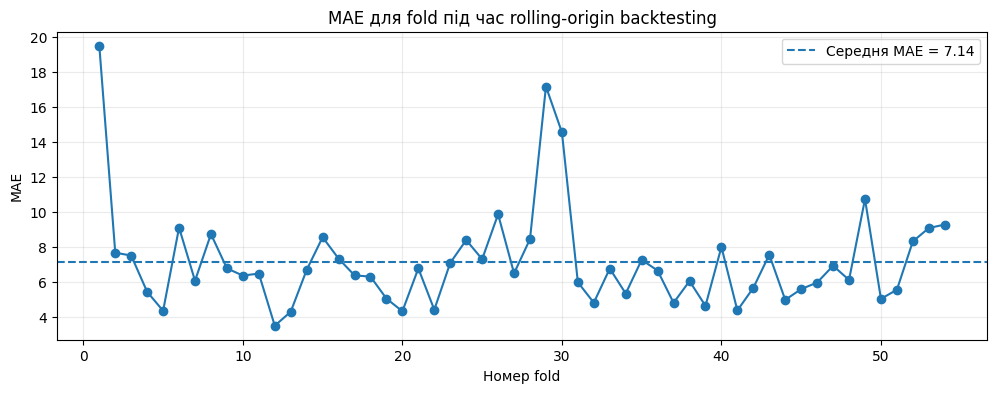

Варіативність MAE між fold показує, що якість прогнозу залежить від конкретного часового інтервалу. Якщо розкид значний, модель є менш стабільною до змін у даних.


In [42]:
cv_results_14 = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=14,
    step=14,
    seasonality=7
)

mean_mae_28 = cv_results["MAE"].mean()
mean_mae_14 = cv_results_14["MAE"].mean()

print("Середня MAE, horizon=28:", round(mean_mae_28, 3))
print("Середня MAE, horizon=14:", round(mean_mae_14, 3))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(range(1, len(cv_results_14) + 1), cv_results_14["MAE"], marker="o")
ax.axhline(mean_mae_14, linestyle="--", label=f"Середня MAE = {mean_mae_14:.2f}")
ax.set_title("MAE для fold під час rolling-origin backtesting")
ax.set_xlabel("Номер fold")
ax.set_ylabel("MAE")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

print(
    "Варіативність MAE між fold показує, що якість прогнозу залежить від конкретного "
    "часового інтервалу. Якщо розкид значний, модель є менш стабільною до змін у даних."
)

## 15. Додаткове завдання: прогнозні інтервали

Точковий прогноз показує одне найбільш очікуване значення. На практиці важливо також оцінювати невизначеність.

Використайте інтервал прогнозу SARIMA і визначте, яка частка фактичних значень тестової вибірки потрапила між нижньою та верхньою межами.

Частка фактичних значень усередині прогнозного інтервалу: 97.78%
Кількість покритих спостережень: 88 із 90


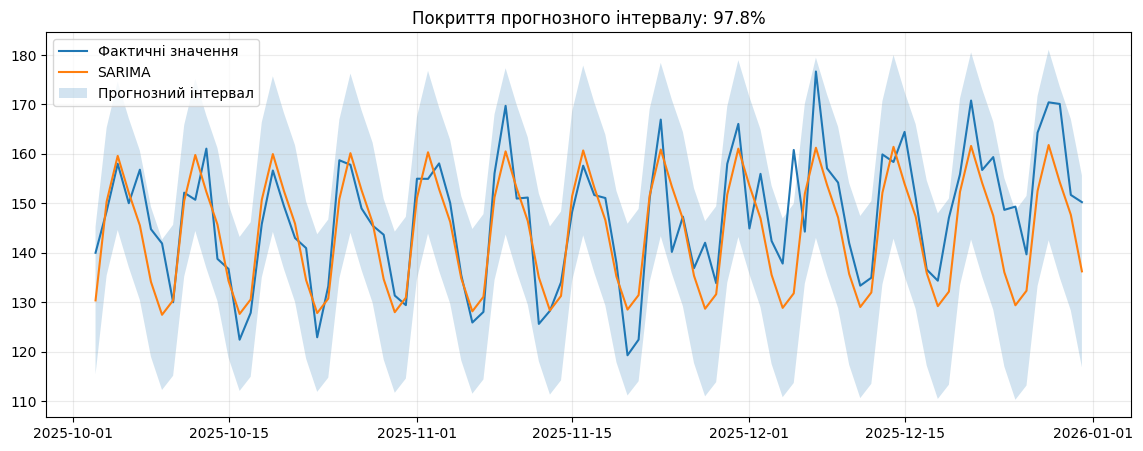

In [43]:
lower = sarima_ci.iloc[:, 0]
upper = sarima_ci.iloc[:, 1]
actual = test["sales"]

inside = (actual >= lower) & (actual <= upper)
coverage = inside.mean()

print(f"Частка фактичних значень усередині прогнозного інтервалу: {coverage:.2%}")
print(f"Кількість покритих спостережень: {inside.sum()} із {len(inside)}")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, actual, label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="SARIMA")
ax.fill_between(
    test.index,
    lower.values,
    upper.values,
    alpha=0.2,
    label="Прогнозний інтервал"
)
ax.legend()
ax.set_title(f"Покриття прогнозного інтервалу: {coverage:.1%}")
ax.grid(alpha=0.25)
plt.show()

## 16. Підсумкове практичне завдання

Виконайте повний цикл прогнозування самостійно.

### Умова

Використайте часовий ряд `df["sales"]`.

### Необхідно

1. Провести первинний аналіз.
2. Перевірити пропуски та регулярність часової шкали.
3. Побудувати графік ряду.
4. Виконати STL-декомпозицію.
5. Виділити останні 60 днів як test.
6. Побудувати seasonal naive.
7. Побудувати одну статистичну модель: ETS або SARIMA.
8. Побудувати одну ML-модель.
9. Обчислити MAE, RMSE, sMAPE і MASE.
10. Порівняти моделі.
11. Побудувати графік найкращого прогнозу.
12. Сформулювати короткий висновок.

### Висновок має містити

- яка модель є найкращою;
- наскільки вона перевершує baseline;
- які закономірності виявлено в ряді;
- які обмеження має отриманий прогноз.

In [44]:
# 1. Первинний аналіз

# Розмір таблиці та тип даних продажів
print("Кількість спостережень:", len(df))
print("Тип даних sales:", df["sales"].dtype)

# Часові межі ряду
print("Початкова дата:", df.index.min().date())
print("Кінцева дата:", df.index.max().date())

# Перші та останні п'ять спостережень
print("\nПерші 5 рядків:")
display(df.head())
print("Останні 5 рядків:")
display(df.tail())

# Основні статистичні характеристики продажів
print("Описові статистики:")
display(
    df["sales"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .to_frame(name="sales")
)

# Перевірка повторів дат
print("Кількість дублікатів дат:", df.index.duplicated().sum())

Кількість спостережень: 1461
Тип даних sales: float64
Початкова дата: 2022-01-01
Кінцева дата: 2025-12-31

Перші 5 рядків:


,sales
date,
2022-01-01,102.654211
2022-01-02,118.300451
2022-01-03,106.941197
2022-01-04,102.241139
2022-01-05,99.014909


Останні 5 рядків:


,sales
date,
2025-12-27,164.284680
2025-12-28,170.415340
2025-12-29,170.091691
2025-12-30,151.683426
2025-12-31,150.225814


Описові статистики:


,sales
count,1461.000000
mean,128.712945
median,128.417545
std,19.788351
min,78.981742
max,270.266786


Кількість дублікатів дат: 0


In [55]:
# 2. Підготовка даних

# Створення окремої копії для підсумкового завдання
df_final = df.copy().sort_index()

# Перевірка частоти спостережень
print("Частота часового ряду:", pd.infer_freq(df_final.index))

# Перевірка наявності усіх дат у межах періоду
expected_dates = pd.date_range(
    start=df_final.index.min(),
    end=df_final.index.max(),
    freq="D"
)

missing_dates = expected_dates.difference(df_final.index)
print("Кількість відсутніх дат:", len(missing_dates))

# Перевірка пропусків у значеннях продажів
print("Кількість пропусків sales:", df_final["sales"].isna().sum())

# Перевірка хронологічного порядку
print("Дати впорядковано:", df_final.index.is_monotonic_increasing)

Частота часового ряду: D
Кількість відсутніх дат: 0
Кількість пропусків sales: 0
Дати впорядковано: True


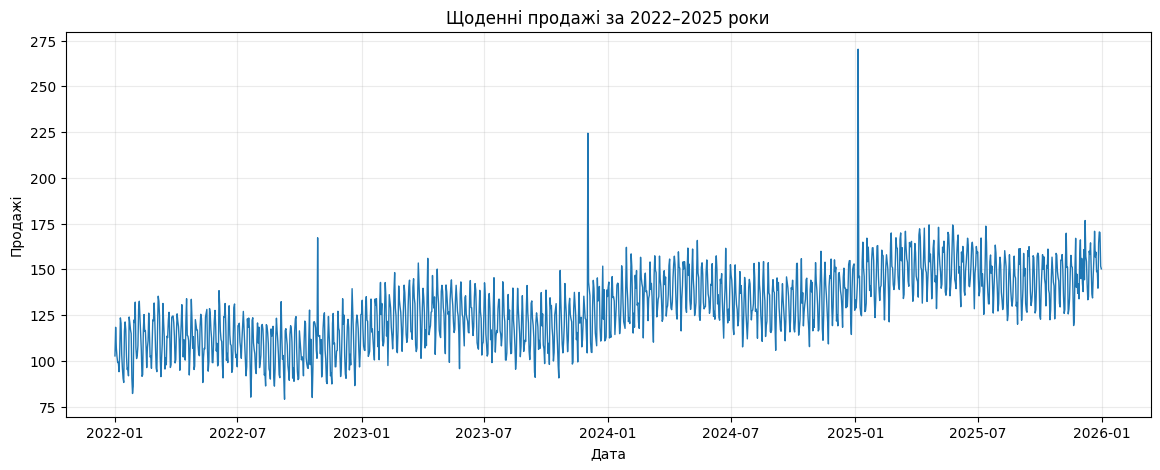

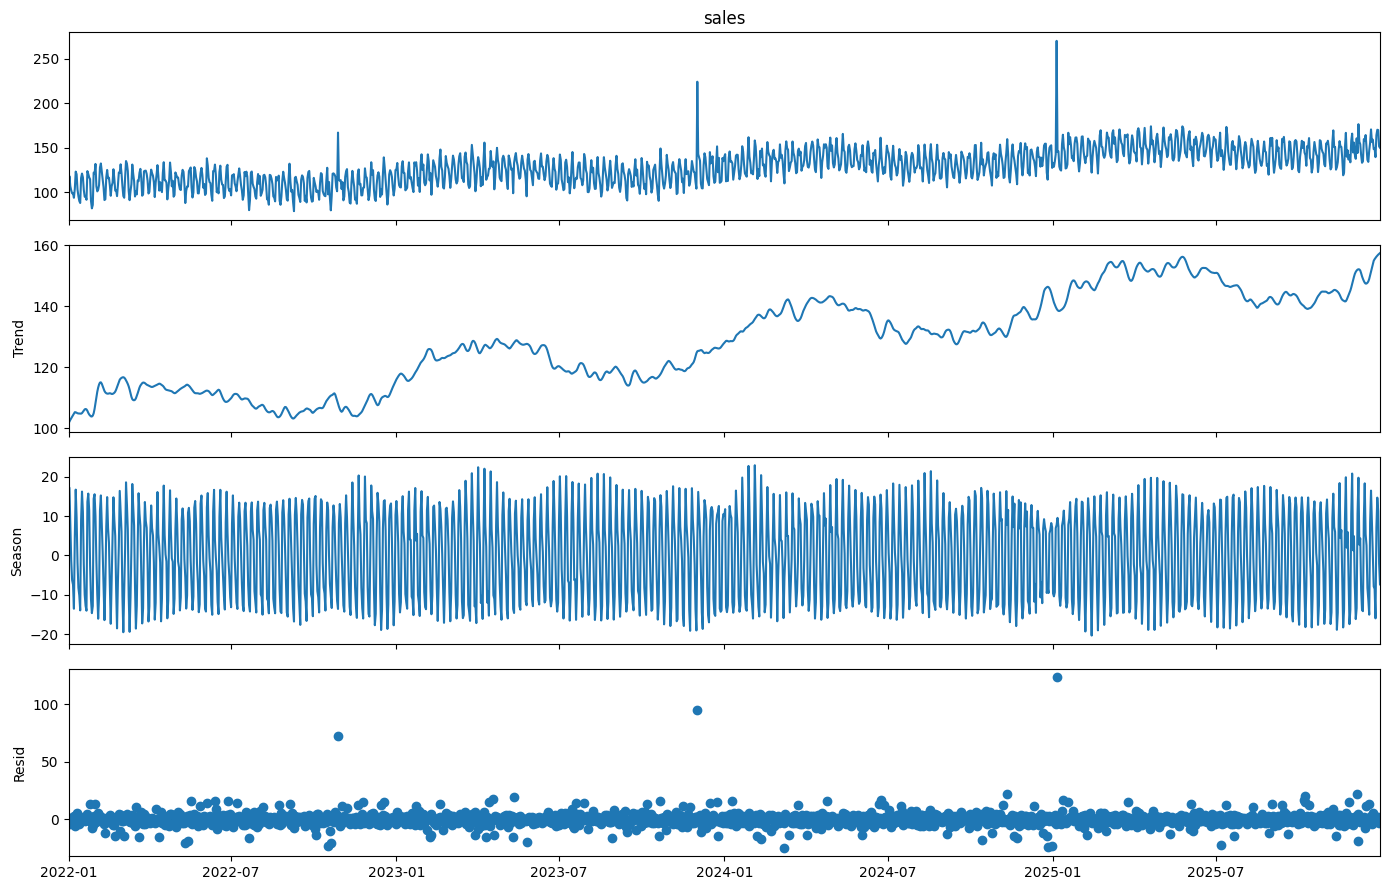

In [48]:
# 3. Візуалізація та STL

# Графік щоденних продажів
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_final.index, df_final["sales"], linewidth=1)
ax.set_title("Щоденні продажі за 2022–2025 роки")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)

plt.show()

# STL-декомпозиція з тижневим періодом сезонності
stl_final = STL(
    df_final["sales"],
    period=7,
    robust=True
).fit()

fig = stl_final.plot()
fig.set_size_inches(14, 9)
plt.tight_layout()
plt.show()

Навчальна вибірка: 1401 спостережень
Період: 2022-01-01 — 2025-11-01

Тестова вибірка: 60 спостережень
Період: 2025-11-02 — 2025-12-31


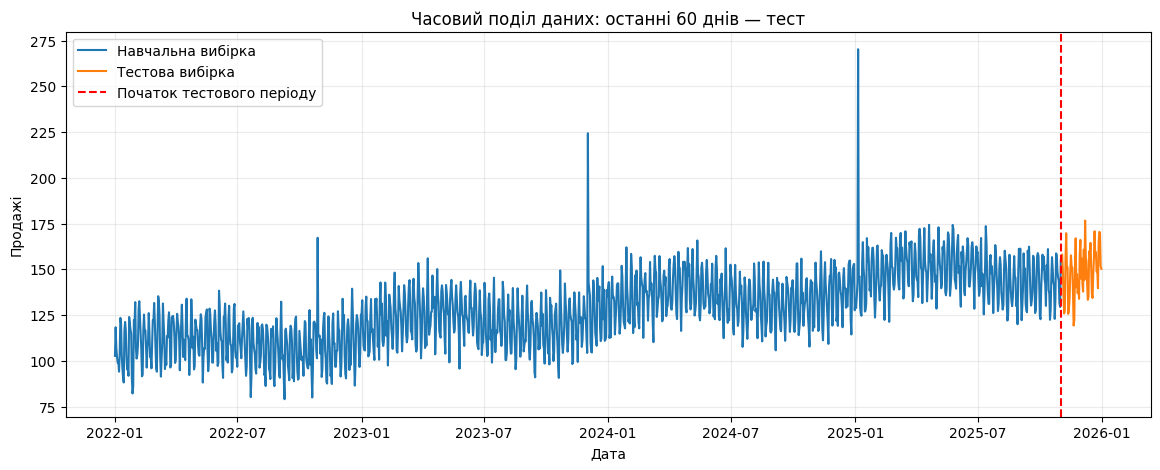

In [49]:
# 4. Поділ на навчальну та тестову вибірки

# Останні 60 днів для перевірки прогнозів
horizon_final = 60

train_final = df_final.iloc[:-horizon_final].copy()
test_final = df_final.iloc[-horizon_final:].copy()

# Розміри та часові межі вибірок
print("Навчальна вибірка:", len(train_final), "спостережень")
print(
    "Період:",
    train_final.index.min().date(),
    "—",
    train_final.index.max().date()
)

print("\nТестова вибірка:", len(test_final), "спостережень")
print(
    "Період:",
    test_final.index.min().date(),
    "—",
    test_final.index.max().date()
)

# Візуалізація поділу
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(train_final.index, train_final["sales"], label="Навчальна вибірка")
ax.plot(test_final.index, test_final["sales"], label="Тестова вибірка")
ax.axvline(
    test_final.index.min(),
    color="red",
    linestyle="--",
    label="Початок тестового періоду"
)

ax.set_title("Часовий поділ даних: останні 60 днів — тест")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.legend()
ax.grid(alpha=0.25)

plt.show()

,Seasonal naive
MAE,7.716983
RMSE,9.675326
sMAPE_%,5.250992
MASE,1.112104


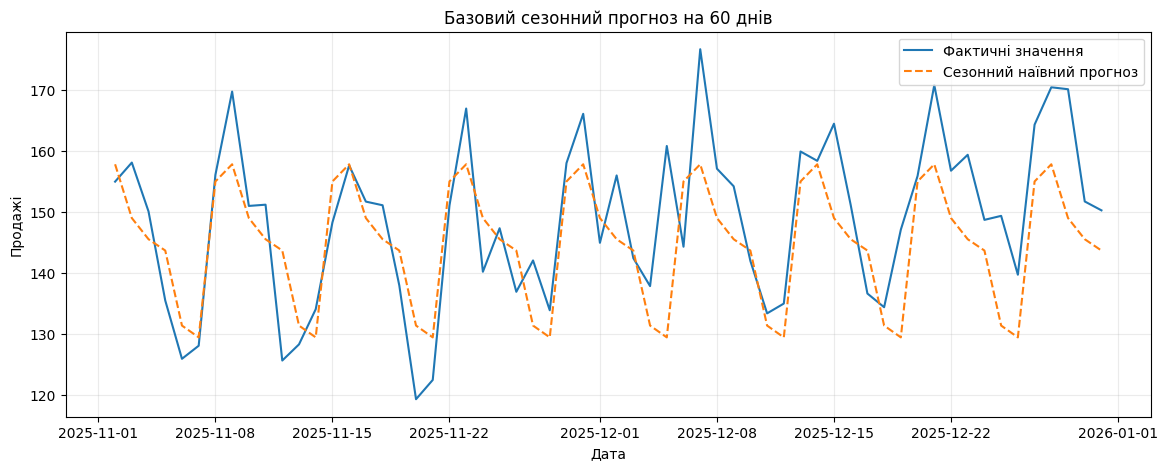

In [50]:
# 5. Базовий сезонний прогноз

# Повторення останніх 7 навчальних значень на весь горизонт
seasonal_naive_pred_final = pd.Series(
    np.resize(
        train_final["sales"].iloc[-7:].to_numpy(),
        len(test_final)
    ),
    index=test_final.index,
    name="Seasonal naive"
)

# Обчислення метрик функцією з попередніх комірок
seasonal_naive_metrics_final = evaluate(
    test_final["sales"],
    seasonal_naive_pred_final,
    train_final["sales"],
    seasonality=7
)

display(
    pd.Series(
        seasonal_naive_metrics_final,
        name="Seasonal naive"
    ).to_frame()
)

# Порівняння прогнозу із фактичними продажами
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(test_final.index, test_final["sales"], label="Фактичні значення")
ax.plot(
    test_final.index,
    seasonal_naive_pred_final,
    label="Сезонний наївний прогноз",
    linestyle="--"
)

ax.set_title("Базовий сезонний прогноз на 60 днів")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.legend()
ax.grid(alpha=0.25)

plt.show()

,ETS
MAE,5.951097
RMSE,7.737209
sMAPE_%,4.033096
MASE,0.857620


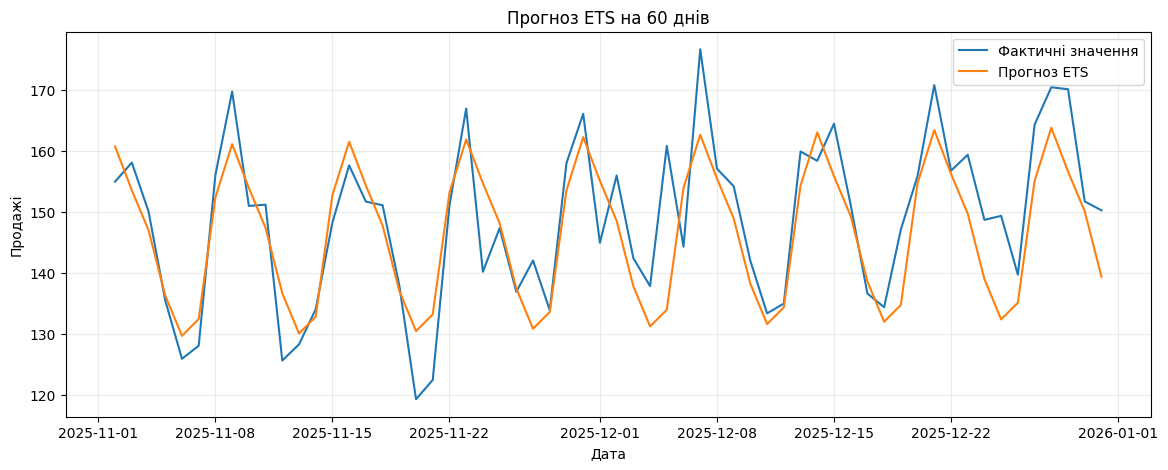

In [51]:
# 6. Статистична модель ETS

# Навчання моделі з адитивним трендом і тижневою сезонністю
ets_model_final = ExponentialSmoothing(
    train_final["sales"].asfreq("D"),
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

# Прогнозування всіх 60 днів з кінця навчального періоду
ets_pred_final = ets_model_final.forecast(len(test_final))

# Обчислення метрик
ets_metrics_final = evaluate(
    test_final["sales"],
    ets_pred_final,
    train_final["sales"],
    seasonality=7
)

display(pd.Series(ets_metrics_final, name="ETS").to_frame())

# Графік прогнозу
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(test_final.index, test_final["sales"], label="Фактичні значення")
ax.plot(test_final.index, ets_pred_final, label="Прогноз ETS")

ax.set_title("Прогноз ETS на 60 днів")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.legend()
ax.grid(alpha=0.25)

plt.show()

,ML
MAE,7.542473
RMSE,9.597364
sMAPE_%,5.149804
MASE,1.086956


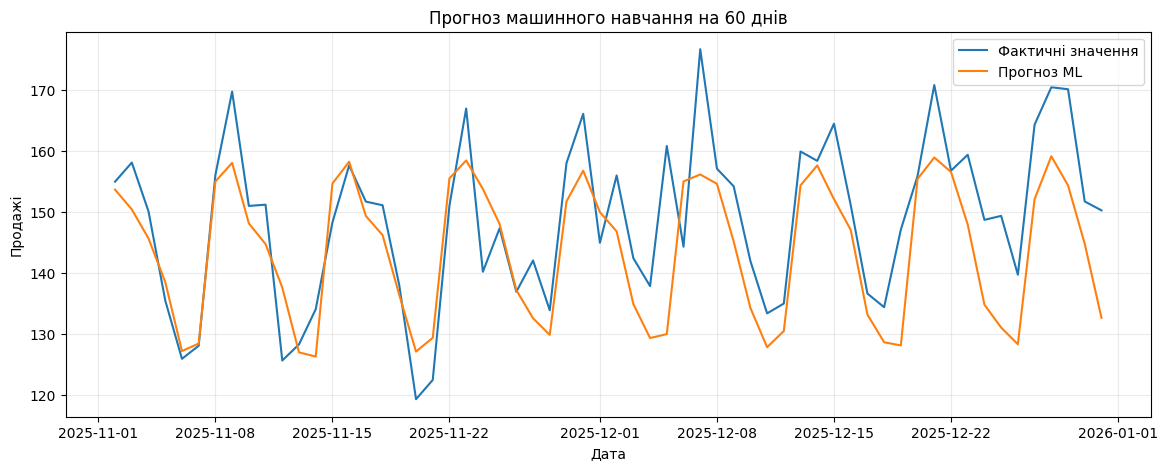

In [52]:
# 7. Модель машинного навчання

# Використання функції створення ознак із попередніх комірок
ml_train_final = make_features(train_final["sales"]).dropna()

X_train_final = ml_train_final.drop(columns="y")
y_train_final = ml_train_final["y"]

# Навчання моделі градієнтного бустингу
ml_model_final = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

ml_model_final.fit(X_train_final, y_train_final)

# Початкова історія містить лише навчальні значення
history_final = train_final["sales"].copy()
ml_predictions_final = []

# Послідовне прогнозування кожного дня тестового періоду
for date in test_final.index:
    # Додавання майбутньої дати з поки невідомим значенням
    history_final.loc[date] = np.nan

    # Ознаки поточного дня обчислюються з попередньої історії
    features_next = (
        make_features(history_final)
        .iloc[[-1]]
        .drop(columns="y")
    )

    prediction = ml_model_final.predict(features_next)[0]
    ml_predictions_final.append(prediction)

    # Для наступних кроків використовується власний прогноз
    history_final.loc[date] = prediction

# Збереження прогнозу із відповідними датами
ml_pred_final = pd.Series(
    ml_predictions_final,
    index=test_final.index,
    name="ML"
)

# Обчислення метрик
ml_metrics_final = evaluate(
    test_final["sales"],
    ml_pred_final,
    train_final["sales"],
    seasonality=7
)

display(pd.Series(ml_metrics_final, name="ML").to_frame())

# Графік прогнозу
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(test_final.index, test_final["sales"], label="Фактичні значення")
ax.plot(test_final.index, ml_pred_final, label="Прогноз ML")

ax.set_title("Прогноз машинного навчання на 60 днів")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.legend()
ax.grid(alpha=0.25)

plt.show()

In [53]:
# 8. Порівняння метрик

# Формування спільної таблиці результатів
comparison_final = pd.DataFrame({
    "Seasonal naive": seasonal_naive_metrics_final,
    "ETS": ets_metrics_final,
    "ML": ml_metrics_final
}).T

# Сортування моделей за середньою абсолютною помилкою
comparison_final = comparison_final.sort_values("MAE")
display(comparison_final.round(4))

# Визначення найкращої моделі за MAE
best_model_final = comparison_final["MAE"].idxmin()
best_mae_final = comparison_final.loc[best_model_final, "MAE"]

# Обчислення зменшення MAE порівняно з базовим прогнозом
baseline_mae_final = comparison_final.loc["Seasonal naive", "MAE"]

improvement_final = (
    (baseline_mae_final - best_mae_final)
    / baseline_mae_final * 100
)

print("Найкраща модель за MAE:", best_model_final)
print(f"MAE найкращої моделі: {best_mae_final:.4f}")
print(f"Зменшення MAE порівняно з базовою моделлю: {improvement_final:.2f}%")

# Визначення найкращої моделі за кожною метрикою
print("\nНайкращі моделі за окремими метриками:")
print(comparison_final.idxmin())

,MAE,RMSE,sMAPE_%,MASE
ETS,5.9511,7.7372,4.0331,0.8576
ML,7.5425,9.5974,5.1498,1.0870
Seasonal naive,7.7170,9.6753,5.2510,1.1121


Найкраща модель за MAE: ETS
MAE найкращої моделі: 5.9511
Зменшення MAE порівняно з базовою моделлю: 22.88%

Найкращі моделі за окремими метриками:
MAE        ETS
RMSE       ETS
sMAPE_%    ETS
MASE       ETS
dtype: object


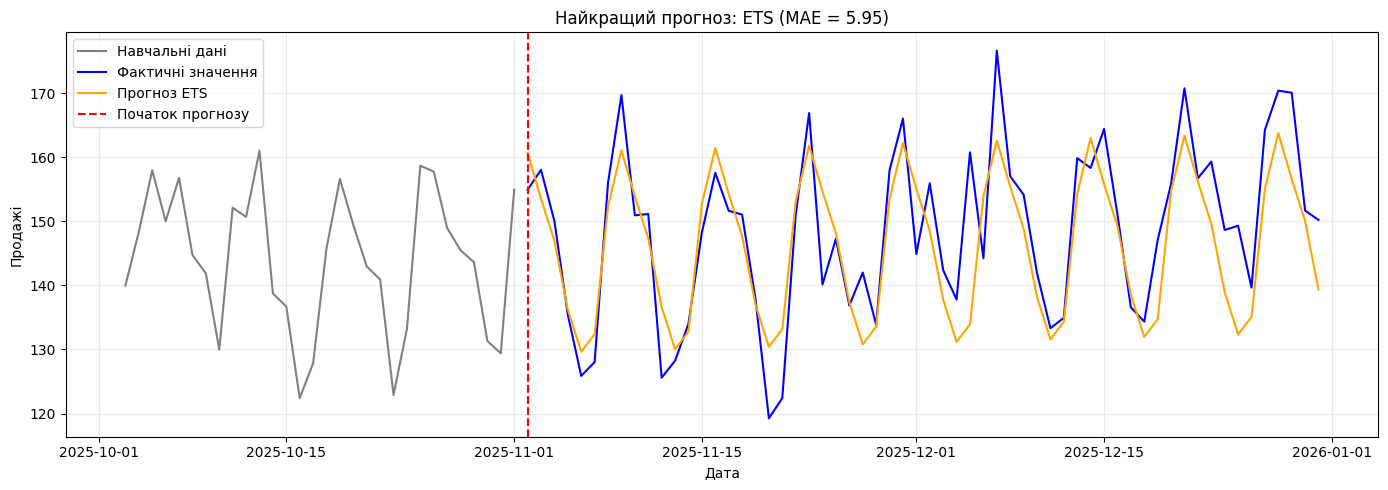

In [54]:
# 9. Фінальний графік

# Вибір прогнозу найкращої моделі за MAE
predictions_final = {
    "Seasonal naive": seasonal_naive_pred_final,
    "ETS": ets_pred_final,
    "ML": ml_pred_final
}

best_pred_final = predictions_final[best_model_final]

# Побудова графіка з останніми 30 днями навчальної вибірки
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    train_final.index[-30:],
    train_final["sales"].iloc[-30:],
    label="Навчальні дані",
    color="gray"
)

ax.plot(
    test_final.index,
    test_final["sales"],
    label="Фактичні значення",
    color="blue"
)

ax.plot(
    test_final.index,
    best_pred_final,
    label=f"Прогноз {best_model_final}",
    color="orange"
)

# Позначення початку тестового періоду
ax.axvline(
    test_final.index.min(),
    color="red",
    linestyle="--",
    label="Початок прогнозу"
)

ax.set_title(
    f"Найкращий прогноз: {best_model_final} "
    f"(MAE = {best_mae_final:.2f})"
)
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Підсумковий висновок

Напишіть 5–8 речень академічним стилем.

**Висновок:**

Під час виконання практичного завдання проведено аналіз часового ряду щоденних продажів за 2022–2025 роки та побудовано прогноз на останні 60 днів. У даних виявлено загальну тенденцію до зростання, виражену тижневу сезонність, повільні річні коливання та окремі викиди. Порівняно сезонний наївний прогноз, модель ETS і модель градієнтного бустингу з рекурсивним прогнозуванням. Найкращою за всіма чотирма метриками виявилася ETS: MAE = 5,9511, RMSE = 7,7372, sMAPE = 4,0331 %, MASE = 0,8576. Порівняно із сезонним наївним прогнозом вона зменшила MAE на 22,88 %. Отриманий прогноз відтворює основні тижневі коливання, проте не повністю передає випадкові зміни та різкі піки продажів. Висновок щодо переваги ETS стосується дослідженого тестового періоду, тому для оцінювання стабільності результатів потрібна додаткова перевірка на інших часових відрізках.

## 17. Контрольні запитання

1. Чому не можна випадково перемішувати часовий ряд перед train/test split?
2. Для чого потрібна базова модель?
3. Чим naive відрізняється від seasonal naive?
4. Що показує MAE?
5. Чому MAPE може бути проблемною за наявності нульових значень?
6. Що означає параметр сезонності `s` у SARIMA?
7. Навіщо використовувати `shift(1)` перед обчисленням rolling-ознак?
8. Що таке витік даних у часових рядах?
9. Навіщо потрібен rolling-origin backtesting?
10. Чому найскладніша модель не обов'язково дає найкращий прогноз?

**Відповіді:**

1. Випадкове перемішування порушує хронологічний порядок і може призвести до використання майбутніх спостережень для прогнозування минулого. Через це оцінка якості моделі буде завищеною.

2. Базова модель забезпечує простий орієнтир для порівняння та допомагає визначити, чи покращує складніша модель якість прогнозу.

3. Наївний прогноз повторює останнє відоме значення. Сезонний наївний прогноз повторює значення відповідного періоду останнього відомого сезонного циклу, наприклад того самого дня тижня.

4. MAE — середня абсолютна помилка між фактичними та прогнозованими значеннями. Вона показує, на скільки одиниць у середньому помиляється модель.

5. У формулі MAPE помилка ділиться на фактичне значення, тому за нульових значень виникає ділення на нуль. За значень, близьких до нуля, показник може бути надмірно великим.

6. Параметр s у SARIMA визначає кількість спостережень у сезонному циклі. Наприклад, s=7 відповідає тижневій сезонності щоденних даних, а s=12 — річній сезонності місячних.

7. shift(1) зсуває значення на один крок, щоб ковзні характеристики обчислювалися лише за попередніми спостереженнями. Це виключає поточне цільове значення з ознак.

8. Витік даних — використання під час навчання або формування прогнозу інформації, яка ще не була доступною на момент прогнозування. Наприклад, використання фактичних майбутніх продажів у лагових ознаках.

9. Покрокова ретроспективна перевірка оцінює модель на кількох послідовних часових відрізках із перенесенням початку прогнозу вперед. Вона допомагає перевірити стабільність якості моделі.

10. Складна модель може перенавчатися, відтворювати випадковий шум або потребувати більшої кількості даних. Простіша модель, яка добре враховує закономірності ряду, може забезпечувати точніший прогноз.
